<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/03_RegresionLineal(2da_Parte).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/03_RegresionLineal(2da_Parte).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión Lineal (2da parte)

> **Regresión lineal múltiple** para predecir el precio de venta de vehículos usados. El proceso sigue estos pasos:
>
> 1. **Todas las variables numéricas** como punto de partida (incluidas `Year` y `Kilometer`). Las correlaciones con el precio se usan para explorar los datos, no para descartar variables.
> 2. **Logaritmo del precio** como variable de salida, con las variables de entrada en su escala original.
> 3. **VIF con intercepto** (`check_vif(..., intercepto=True)`) para detectar la colinealidad.
> 4. **Selección hacia atrás**, una variable a la vez: primero por VIF (> 10) y luego por *p-value* (> 0.05) con errores estándar robustos (HC3).
> 5. **Diagnóstico de los supuestos** del modelo (homocedasticidad, normalidad de los residuos, observaciones influyentes).
> 6. **Evaluación en dólares** con el conjunto de prueba real (`01_carDetailsV4_Prue.csv`).
>
> Usa los datos preparados en `01_PreparaciónDataset01Regresion` (categorías raras de `Owner` y `Seller Type` agrupadas en `Otro`).

## 1. Librerias y configuraciones previas

In [204]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np


# Preprocesado y modelado
# ==============================================================================

#Separar los datos entrenamiento y prueba
from sklearn.model_selection import train_test_split

#Escalar Variables
from sklearn.preprocessing import MinMaxScaler

#Creación de modelo
from statsmodels import api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera

#Evaluación del modelo
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                            median_absolute_error)

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Interactuar con el sistema operativo y solicitudes HTTP
# ==============================================================================
import os
import sys
import requests
from urllib.parse import urljoin

# Configuración warnings
# ==============================================================================
import warnings
# Se ocultan solo los avisos informativos de versiones; los demás avisos siguen visibles
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
# Aviso de matplotlib que genera internamente sm.qqplot al personalizar el color de los puntos (no afecta el resultado)
warnings.filterwarnings('ignore', message='.*redundantly defined by the')

In [205]:
# Parametros globales
# ==============================================================================

# URL base de GitHub para el repositorio
GITHUB_BASE_URL = 'https://raw.githubusercontent.com/mrbedoya/ml-2026/main/'

# Nombres de los archivos requeridos
DATASET_FILE_NAME = '01_carDetailsV4_Prep.csv'
DATASET_FILE_NAME_PRUE = '01_carDetailsV4_Prue.csv'
UTILS_FILE_NAME = 'funciones.py'

# Nombres de los directorios para utilidades y datasets
DATASETS_PATH = 'datasets/'
UTILS_PATH = 'utils/'

# URL completa del dataset y utils en GitHub (urljoin evita errores con las barras)
github_dataset_url = urljoin(GITHUB_BASE_URL, DATASETS_PATH + DATASET_FILE_NAME)
github_dataset_url_prue = urljoin(GITHUB_BASE_URL, DATASETS_PATH + DATASET_FILE_NAME_PRUE)
github_utils_url = urljoin(GITHUB_BASE_URL, UTILS_PATH + UTILS_FILE_NAME)

# Rutas locales completas de datasets y utils
local_dataset_path = os.path.join(DATASETS_PATH, DATASET_FILE_NAME)
local_dataset_path_prue = os.path.join(DATASETS_PATH, DATASET_FILE_NAME_PRUE)
local_utils_path = os.path.join(UTILS_PATH, UTILS_FILE_NAME)

### (Opcional) Cargar datos desde Google Drive

La celda siguiente muestra una **alternativa** para trabajar con archivos guardados en Google Drive, en vez de descargarlos desde GitHub. Se deja comentada porque en este notebook usamos la descarga directa desde el repositorio (más fácil de reproducir para cualquier estudiante), pero queda como referencia por si prefieres montar tu propio Drive.

In [206]:
## Cargar datos desde Google Drive
## ==============================================================================

#from google.colab import drive

## Montar Google Drive
#drive.mount('/gdrive')

## Establece el directorio de trabajo dentro de directorio especificado en Google Drive
#os.chdir("/gdrive/MyDrive/01_Academia/02_Cursos/20260401_ApredinzajeAutomáticoI_UdeA/")

## Listar archivos de directorio
##!ls

In [207]:
# Funcion local para la carga de archivos
# ==============================================================================

def download_file(url, path, description, force=False, timeout=30):
    '''
    Descarga un archivo desde una URL y lo guarda localmente en un path.
    Si el archivo ya existe no se vuelve a descargar (usar force=True para obligarlo).

    Args:
        url (str): URL del archivo
        path (str): Ruta local de destino
        description (str): Descripción del archivo
        force (bool): Si es True, descarga aunque el archivo ya exista
        timeout (int): Segundos máximos de espera de la descarga
    Returns:
        None
    '''
    if os.path.exists(path) and not force:
        print(f"{description} ya existe en: {path} (no se vuelve a descargar)")
        return

    print(f"Descargando {description} desde: {url}")

    # Realiza una solicitud HTTP GET a la URL proporcionada
    response = requests.get(url, timeout=timeout)

    # Lanza una excepción si la descarga falla (código de estado HTTP no 200)
    response.raise_for_status()

    # Abre el archivo local en modo de escritura binaria ('wb')
    with open(path, 'wb') as f:
        # Escribe el contenido binario de la respuesta HTTP en el archivo local
        f.write(response.content)

    # Imprime un mensaje confirmando que la descarga fue exitosa y la ruta de guardado
    print(f"{description} descargado exitosamente a: {path}")

In [208]:
# Configuración entorno Colab
# ==============================================================================

# Creación de directorios locales
os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(UTILS_PATH, exist_ok=True)

# Descarga de archivos
download_file(github_dataset_url, local_dataset_path, "dataset")
download_file(github_dataset_url_prue, local_dataset_path_prue, "dataset de prueba")
download_file(github_utils_url, local_utils_path, "funciones")

dataset ya existe en: datasets/01_carDetailsV4_Prep.csv (no se vuelve a descargar)
dataset de prueba ya existe en: datasets/01_carDetailsV4_Prue.csv (no se vuelve a descargar)
funciones ya existe en: utils/funciones.py (no se vuelve a descargar)


## 2. Funciones

En esta sección importamos las funciones reutilizables de `funciones.py` (descargado arriba) y definimos las funciones propias de este notebook: construir el modelo y calcular las métricas en dólares.

In [209]:
# Funciones externas
# ==============================================================================

# Añade la ruta definida en 'UTILS_PATH' al 'sys.path' para que Python pueda encontrar módulos
sys.path.append(UTILS_PATH)

# Importa funciones externas
from funciones import multiple_plot, tidy_corr_matrix, check_vif

In [210]:
# Función para construir un modelo de regresión lineal por medio de statsmodels.api

def build_model(X, y, robusto=True):
    '''
    Crea y entrena un modelo de regresión lineal (OLS) con statsmodels e imprime su resumen.

    Args:
        X (DataFrame): variables de entrada (a las que se les adiciona la constante)
        y (Series): variable de salida
        robusto (bool): si es True usa errores estándar robustos HC3. Los coeficientes y el R2 son los
                        mismos; cambian los errores estándar, los p-values y los intervalos de confianza,
                        que siguen siendo válidos aunque haya heterocedasticidad.
    Returns:
        tuple: (modelo ajustado, 'X' con la constante adicionada)
    '''

    #A los datos de entrada 'X' se le adiciona una constante
    X = sm.add_constant(X)

    #Se crea y se entrena el modelo de regresión lineal (statsmodels.api)
    modelo = sm.OLS(y, X).fit(cov_type='HC3' if robusto else 'nonrobust')

    #imprime el resumen del modelo creado
    print(modelo.summary())

    return modelo, X

In [211]:
# Función para calcular las métricas de error en la escala original del precio (dólares)

def metricas_precio(precio_real, precio_pred):
    '''
    Calcula R2, RMSE, MAE y MedAE entre el precio real y el precio predicho (ambos en dólares).
    '''
    return {'R2': r2_score(precio_real, precio_pred),
            'RMSE': np.sqrt(mean_squared_error(precio_real, precio_pred)),
            'MAE': mean_absolute_error(precio_real, precio_pred),
            'MedAE': median_absolute_error(precio_real, precio_pred)}

## 3. Carga del dataset

In [212]:
#Se crea un dataframe d con los datos obtenidos de archivo de entrada
d = pd.read_csv(local_dataset_path)

In [213]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Price               1436 non-null   float64
 1   Year                1436 non-null   int64  
 2   Kilometer           1436 non-null   int64  
 3   Engine              1436 non-null   float64
 4   Length              1436 non-null   float64
 5   Width               1436 non-null   float64
 6   Height              1436 non-null   float64
 7   Seating Capacity    1436 non-null   float64
 8   Fuel Tank Capacity  1436 non-null   float64
 9   Fuel Type           1436 non-null   object 
 10  Transmission        1436 non-null   object 
 11  Owner               1436 non-null   object 
 12  Seller Type         1436 non-null   object 
 13  Drivetrain          1436 non-null   object 
 14  PriceRange          1436 non-null   int64  
dtypes: float64(7), int64(3), object(5)
memory usage: 168.4+

## 4. Visualización de datos

### Variables de entrada

In [214]:
#Lista de variables categóricas
catCols = d.select_dtypes(include = ["object", 'category']).columns.tolist()

d[catCols].head(2)

,Fuel Type,Transmission,Owner,Seller Type,Drivetrain
0,Petrol,Manual,First,Individual,FWD
1,Petrol,Manual,First,Individual,FWD


In [215]:
#Lista de variables numéricas

numCols=d.select_dtypes(include = ['float64','float64','int32','int64']).columns.tolist()
d[numCols].head(2)

,Price,Year,Kilometer,Engine,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,PriceRange
0,9300.0000,2020,39000,1197.0000,3995.0000,1775.0000,1505.0000,5.0000,37.0000,0
1,7500.0000,2019,31000,1197.0000,3985.0000,1734.0000,1505.0000,5.0000,45.0000,0


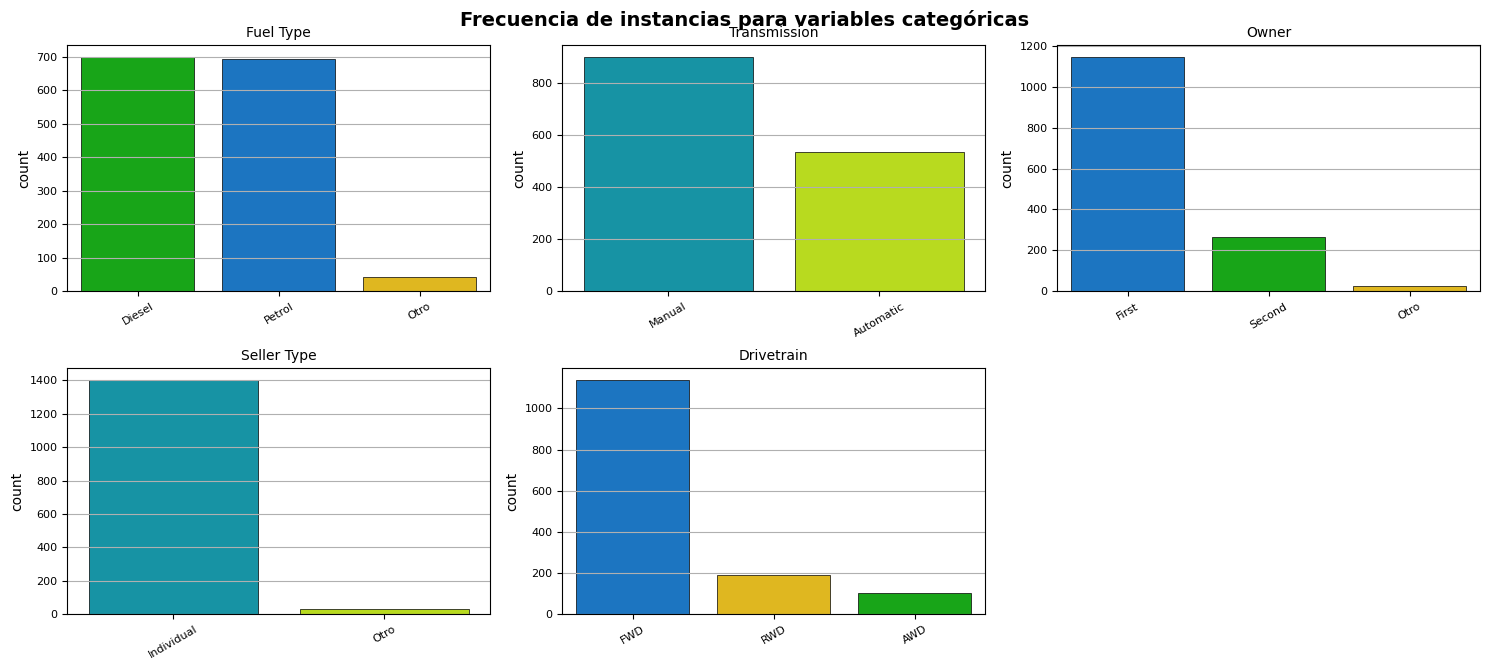

In [216]:
##Visualización de frecuencia de instancias para variables categóricas
multiple_plot(3, d , catCols, None, 'countplot', 'Frecuencia de instancias para variables categóricas',30)

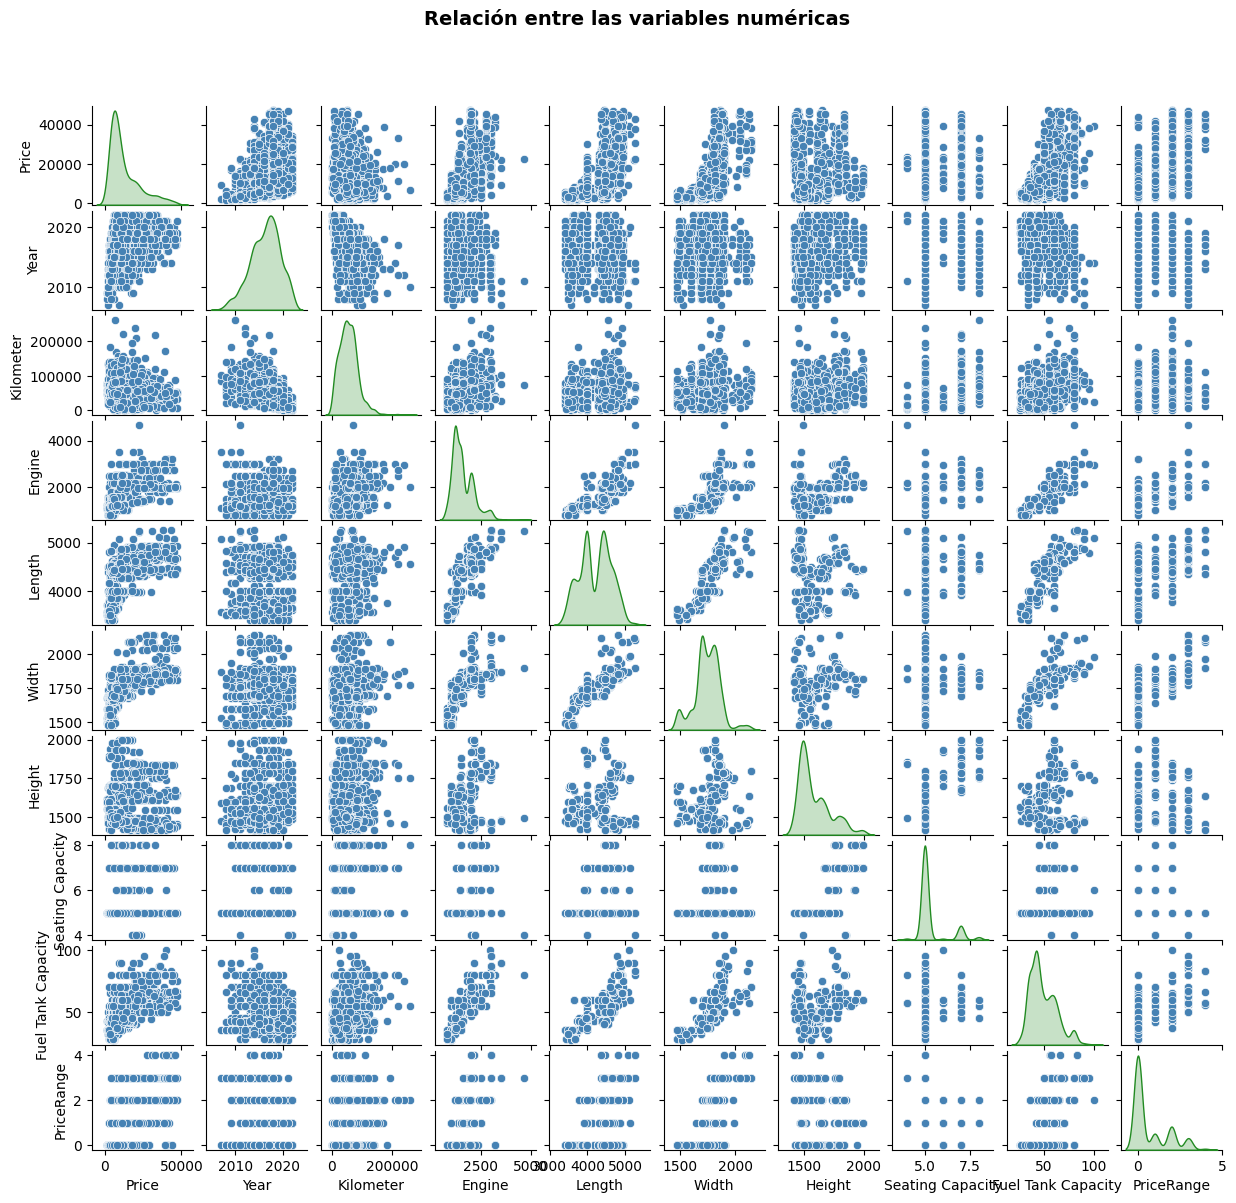

In [217]:
#Visualización de variables numéricas con respecto al precio
multiple_plot(1, d , numCols, None, 'scatterplot', 'Relación entre las variables numéricas',30)

### Variable de salida

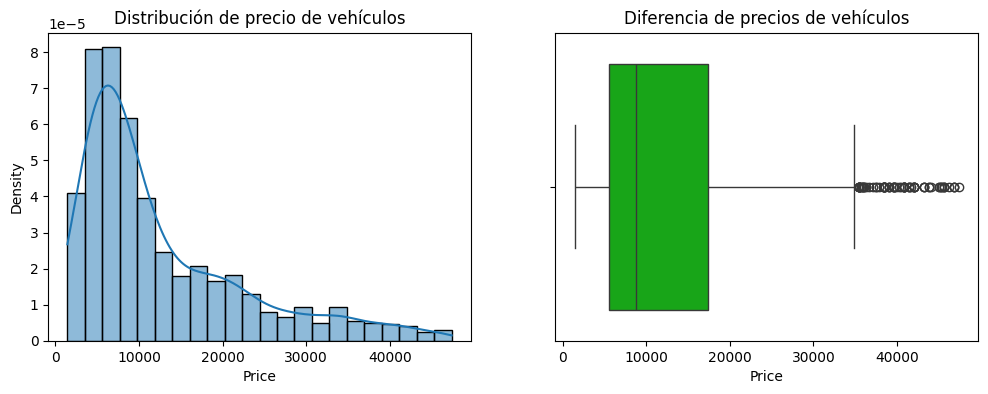

In [218]:
#Histograma y caja de bigotes del precio de los vehículos

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.title('Distribución de precio de vehículos')
sns.histplot(d.Price, kde=True, stat='density')

plt.subplot(1,2,2)
plt.title('Diferencia de precios de vehículos')
sns.boxplot(x=d.Price, palette='nipy_spectral')

plt.show()

In [219]:
pd.set_option('display.float_format', lambda x: '%.0f' % x)

print(d.Price.describe(percentiles = [0.25,0.50,0.75,0.85,0.90,0.95,0.975,1]))

count    1436
mean    12664
std      9999
min      1440
25%      5520
50%      8790
75%     17400
85%     23025
90%     28590
95%     35400
97.5%   39938
100%    47400
max     47400
Name: Price, dtype: float64


In [220]:
# Eliminar el valor 'Price' de la lista
numCols.remove('Price')

## 5. Preparación de datos

### Transformación de la variable de salida

El precio tiene una distribución sesgada a la derecha y la variación de los errores crece con el precio. Con el **logaritmo** del precio la distribución es más simétrica, la varianza es más estable y los coeficientes se interpretan como cambios porcentuales en el precio. Con este conjunto de datos el logaritmo ajusta mejor que otras transformaciones como la raíz cúbica o la raíz cuadrada.

In [221]:
#Transformación y = ln(y) Logaritmo natural

d['Price'] = np.log(d['Price'])

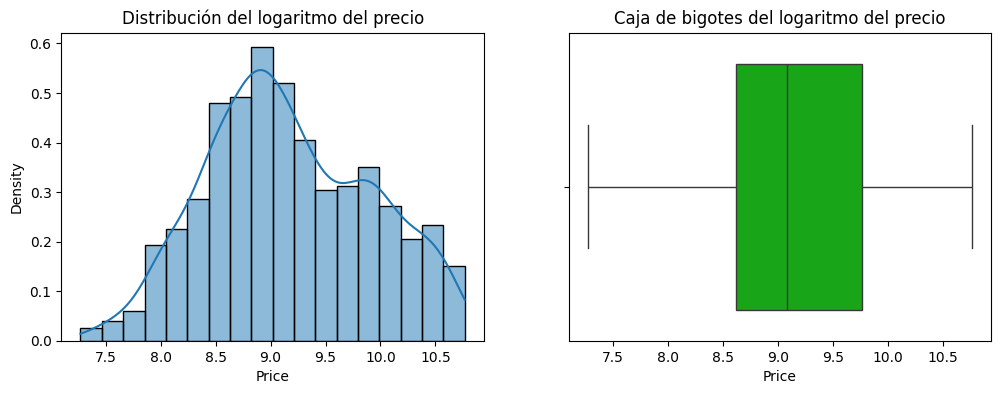

In [222]:
#Histograma y caja de bigotes del logaritmo del precio de los vehículos

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.title('Distribución del logaritmo del precio')
sns.histplot(d.Price, kde=True, stat='density')

plt.subplot(1,2,2)
plt.title('Caja de bigotes del logaritmo del precio')
sns.boxplot(x=d.Price, palette='nipy_spectral')

plt.show()

### Transformaciones a las variables de entrada

Las variables de entrada se dejan en su escala original: elevarlas al cuadrado (`Year`, `Length`, `Width`, `Fuel Tank Capacity`) no mejora el ajuste de forma apreciable y hace más difícil interpretar los coeficientes. Si la gráfica de residuos vs. predicción mostrara curvatura, se puede volver a evaluar una transformación.

### Correlaciones (exploración)

Las correlaciones con el precio sirven para **explorar** los datos, no para descartar variables: una variable con una correlación moderada (por ejemplo `Year`) puede ser muy importante al combinarla con las demás. Por eso todas las variables numéricas pasan a la selección del modelo.

In [223]:
#Generación de la matriz de correlación (incluye la variable de salida 'Price')
matrizCorr = d[['Price']+numCols].corr()

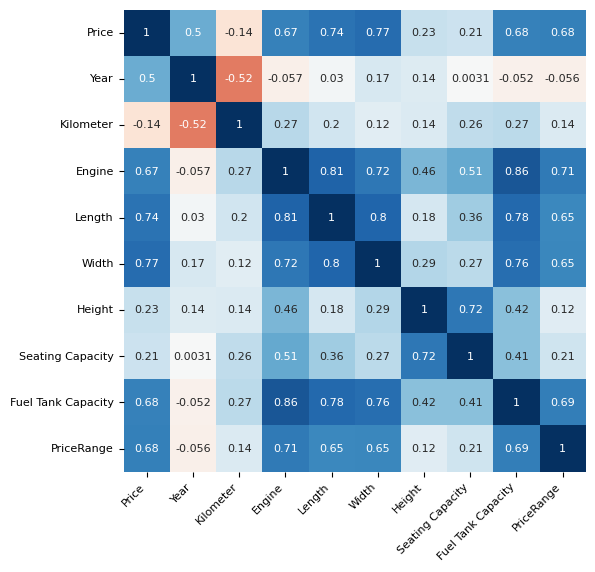

In [224]:
# Mapa de calor (Heatmap) de la matriz de correlaciones

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 6))

sns.heatmap(
    matrizCorr,
    annot     = True,
    cbar      = False,
    annot_kws = {"size": 8},
    vmin      = -1,
    vmax      = 1,
    center    = 0,
    cmap      = 'RdBu', #sns.diverging_palette(20, 220, n=200),
    square    = True,
    ax        = ax
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation = 45,
    horizontalalignment = 'right',
)


ax.tick_params(labelsize = 8)

In [225]:
#Matriz de correlación ordenada

pd.set_option('display.float_format', lambda x: '%.4f' % x)

#Creación de la matriz
df_corr = tidy_corr_matrix(matrizCorr)

#Correlaciones de cada variable numérica con el precio
df_filtrado = df_corr.loc[df_corr['variable_2'] == 'Price']
df_filtrado[['variable_1', 'r', 'abs_r']]

,variable_1,r,abs_r
50,Width,0.7674,0.7674
40,Length,0.7355,0.7355
90,PriceRange,0.6805,0.6805
80,Fuel Tank Capacity,0.6795,0.6795
30,Engine,0.6748,0.6748
10,Year,0.4980,0.4980
60,Height,0.2313,0.2313
70,Seating Capacity,0.2147,0.2147
20,Kilometer,-0.1385,0.1385


### Creación de Variables Dummies

Con `drop_first=True` se elimina una categoría de referencia por variable (la primera alfabéticamente: `First`, `Individual`, `Diesel`, `Automatic`, `AWD`), que en estos datos es siempre una categoría con muchas filas.

In [226]:
# Aplicación de la función de get_dummies

d = pd.get_dummies(d, dtype=int, drop_first=True)

In [227]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Price                1436 non-null   float64
 1   Year                 1436 non-null   int64  
 2   Kilometer            1436 non-null   int64  
 3   Engine               1436 non-null   float64
 4   Length               1436 non-null   float64
 5   Width                1436 non-null   float64
 6   Height               1436 non-null   float64
 7   Seating Capacity     1436 non-null   float64
 8   Fuel Tank Capacity   1436 non-null   float64
 9   PriceRange           1436 non-null   int64  
 10  Fuel Type_Otro       1436 non-null   int64  
 11  Fuel Type_Petrol     1436 non-null   int64  
 12  Transmission_Manual  1436 non-null   int64  
 13  Owner_Otro           1436 non-null   int64  
 14  Owner_Second         1436 non-null   int64  
 15  Seller Type_Otro     1436 non-null   i

## 6. Creación del modelo

### Dividir el conjunto de datos

In [228]:
#Se establece las variables de entrada 'X' y la variable de salida 'y'

X = d.drop(columns='Price')
y = d['Price']

In [229]:
# División de los datos en train y test

#En este caso, el 80% de los datos se utilizarán para entrenar el modelo.

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y,
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True
                                    )

### Escalar Variables

La regresión lineal por mínimos cuadrados **no necesita** escalar las variables: el escalado no cambia el R², los p-values ni el VIF (solo cambia la escala de los coeficientes). Se escala para mantener la misma preparación que en los demás notebooks del curso.

In [230]:
#Se establecen las variables numéricas a escalar

#Num_vars contiene las variables numéricas de entrada (se conserva el orden de numCols)
num_vars = [col for col in numCols if col in X.columns]

print(num_vars)

['Year', 'Kilometer', 'Engine', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity', 'PriceRange']


In [231]:
#Escalar Variables númericas

pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Se crea un objeto MinMaxScaler
scaler = MinMaxScaler()

# Se escalan los valores del dataset entrenamiento y prueba de las columnas numéricas
X_train[num_vars] = scaler.fit_transform(X_train[num_vars])
X_test[num_vars] = scaler.transform(X_test[num_vars])

X_train[num_vars].head()

,Year,Kilometer,Engine,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,PriceRange
717,0.8000,0.0592,0.4344,0.5714,0.4820,0.0000,0.2500,0.3382,0.5000
1018,0.5333,0.3252,0.6303,0.2827,0.3529,0.8877,0.7500,0.4853,0.2500
906,0.5333,0.1757,0.2144,0.5897,0.3829,0.1192,0.2500,0.2353,0.0000
117,0.3333,0.4630,0.8092,0.7054,0.5480,0.7496,0.7500,0.7794,0.5000
125,0.2000,1.0000,0.4455,0.6247,0.4429,0.5855,1.0000,0.4118,0.5000


### Selección de variables

#### Colinealidad

El VIF (*Variance Inflation Factor*) mide cuánto se explica una variable a partir de las demás. Se calcula **con intercepto** (`intercepto=True`): sin intercepto el VIF de variables escaladas entre 0 y 1 sale inflado y puede llevar a eliminar variables que no están colineales. Si existe alguna *feature* con VIF > 10 (siendo estrictos, VIF > 5) se convierte en candidata a eliminar; un VIF `inf` indica colinealidad perfecta.

In [232]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables (con intercepto)

check_vif(X_train, intercepto=True)

,Features,VIF
0,Engine,7.9900
1,Length,6.0700
2,Fuel Tank Capacity,5.5700
3,Drivetrain_FWD,5.1700
4,Width,4.4300
5,Height,4.2100
6,PriceRange,3.6600
7,Seating Capacity,3.5600
8,Drivetrain_RWD,3.2100
9,Fuel Type_Petrol,1.7800


Con este conjunto de datos ninguna variable supera el umbral de 10, por lo que **no se elimina ninguna por colinealidad**. Los VIF más altos corresponden a las variables que miden el tamaño del vehículo (`Engine`, `Length`, `Width`, `Fuel Tank Capacity`): están correlacionadas entre sí, pero aportan información relevante y su VIF es aceptable.

Si en alguna ejecución una variable superara 10, se elimina **solo la de mayor VIF** (`X_train = X_train.drop(columns=['variable'])`), se vuelve a calcular el VIF y se repite hasta que ninguna lo supere. Un VIF `inf` indica colinealidad perfecta: esas variables se resuelven primero.

#### Significancia estadística (p-value)

Con la colinealidad controlada se revisan los *p-values*. Se ajusta el modelo, se identifica la variable con **mayor** *p-value* y, si es mayor a 0.05 (no hay suficiente evidencia de que tenga un efecto significativo sobre el precio una vez consideradas las demás), se elimina. Se elimina **una sola variable por paso** y se vuelve a ajustar el modelo, porque al quitarla cambian los *p-values* de las demás.

Los *p-values* se calculan con errores estándar robustos (HC3), que siguen siendo válidos aunque la varianza de los errores no sea constante. Se revisan después de la colinealidad porque esta infla los errores estándar y hace poco confiables los *p-values*.

##### Paso 1: modelo con todas las variables

In [233]:
# Paso 1: modelo con todas las variables
X_train_modelo = X_train.copy()
modelo_paso, _ = build_model(X_train_modelo, y_train)

# Variables con mayor p-value (candidatas a eliminar)
modelo_paso.pvalues.drop('const').sort_values(ascending=False).head(3)

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     728.6
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:57:24   Log-Likelihood:                 120.33
No. Observations:                1148   AIC:                            -204.7
Df Residuals:                    1130   BIC:                            -113.8
Df Model:                          17                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   7.7760    

,0
Fuel Type_Otro,0.5691
Height,0.3037
Seating Capacity,0.1674


La variable con mayor *p-value* es `Fuel Type_Otro` y es mayor a 0.05: una vez consideradas las demás variables, no hay evidencia de que pertenecer a la categoría `Otro` de combustible modifique el precio. Se elimina solo esta variable y se vuelve a ajustar el modelo.

In [234]:
#Se elimina la variable 'Fuel Type_Otro'
X_train_modelo = X_train_modelo.drop(columns=['Fuel Type_Otro'])

##### Paso 2: modelo sin `Fuel Type_Otro`

In [235]:
# Paso 2: modelo sin `Fuel Type_Otro`
modelo_paso, _ = build_model(X_train_modelo, y_train)

# Variables con mayor p-value (candidatas a eliminar)
modelo_paso.pvalues.drop('const').sort_values(ascending=False).head(3)

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     776.7
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:57:24   Log-Likelihood:                 120.20
No. Observations:                1148   AIC:                            -206.4
Df Residuals:                    1131   BIC:                            -120.6
Df Model:                          16                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   7.7823    

,0
Height,0.3353
Seating Capacity,0.1524
Seller Type_Otro,0.0944


Al volver a ajustar, la variable con mayor *p-value* es `Height` y es mayor a 0.05: la altura no aporta información adicional sobre el precio una vez consideradas el resto de las medidas del vehículo. Se elimina.

In [236]:
#Se elimina la variable 'Height'
X_train_modelo = X_train_modelo.drop(columns=['Height'])

##### Paso 3: modelo sin `Fuel Type_Otro` y `Height`

In [237]:
# Paso 3: modelo sin `Fuel Type_Otro` y `Height`
modelo_paso, _ = build_model(X_train_modelo, y_train)

# Variables con mayor p-value (candidatas a eliminar)
modelo_paso.pvalues.drop('const').sort_values(ascending=False).head(3)

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     825.4
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:57:24   Log-Likelihood:                 119.58
No. Observations:                1148   AIC:                            -207.2
Df Residuals:                    1132   BIC:                            -126.4
Df Model:                          15                                         
Covariance Type:                  HC3                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   7.7767    

,0
Seller Type_Otro,0.0875
Owner_Otro,0.0322
Seating Capacity,0.0128


La variable con mayor *p-value* es `Seller Type_Otro` y es mayor a 0.05 (no hay evidencia suficiente de que el tipo de vendedor `Otro` cambie el precio). Se elimina. Después de este paso todas las variables restantes tienen *p-value* menor a 0.05, por lo que la selección termina.

In [238]:
#Se elimina la variable 'Seller Type_Otro'
X_train_modelo = X_train_modelo.drop(columns=['Seller Type_Otro'])

### Creación del modelo

Se entrena el modelo final con las variables que quedaron después de la selección: en la tabla de coeficientes todas tienen *p-value* menor a 0.05. Con scikit-learn (`LinearRegression`) se obtienen los mismos coeficientes, pero no el resumen estadístico (*p-values*, intervalos de confianza), por eso se usa statsmodels.

In [239]:
# Variables finales del modelo
columnas_finales = list(X_train_modelo.columns)
print(f"Variables iniciales: {X_train.shape[1]} | variables finales: {len(columnas_finales)}")
print(columnas_finales)

#Llamamos la funcion build_model definida al principio de este notebook que crea y entrena el modelo
#con las variables finales (errores estándar robustos HC3)

modelLRegresion, X_train_const = build_model(X_train_modelo, y_train)

Variables iniciales: 17 | variables finales: 14
['Year', 'Kilometer', 'Engine', 'Length', 'Width', 'Seating Capacity', 'Fuel Tank Capacity', 'PriceRange', 'Fuel Type_Petrol', 'Transmission_Manual', 'Owner_Otro', 'Owner_Second', 'Drivetrain_FWD', 'Drivetrain_RWD']
                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     887.5
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        06:57:24   Log-Likelihood:                 117.92
No. Observations:                1148   AIC:                            -205.8
Df Residuals:                    1133   BIC:                            -130.2
Df Model:                          14                                         
Covariance Type:         

### Diagnóstico de los supuestos del modelo

Se revisan los residuos del modelo en entrenamiento:

- **Homocedasticidad** (Breusch-Pagan): p-value menor a 0.05 indica que la varianza de los errores cambia con el nivel de las variables. Si se incumple, los errores estándar robustos (HC3) siguen siendo válidos.
- **Normalidad de los residuos** (Jarque-Bera): afecta sobre todo a los intervalos de confianza con muestras pequeñas; con muchas observaciones es menos crítica.
- **Independencia** (Durbin-Watson): cercano a 2 indica que no hay autocorrelación.
- **Observaciones influyentes** (distancia de Cook): valores mayores a 1 indican puntos que cambian mucho el modelo.

In [240]:
# Diagnóstico errores (residuos) de las predicciones de entrenamiento

#Se realiza la predicción sobre los datos de entrenamiento (en escala logarítmica)
prediccion_train = modelLRegresion.predict(X_train_const)

#Se calculan los residuos: diferencia entre la prediccion y el valor real en los datos de entrenamiento
residuos_train   = prediccion_train - y_train

In [241]:
## Pruebas sobre los supuestos
#bp = het_breuschpagan(residuos_train, X_train_const)
#jb = jarque_bera(residuos_train)
#dw = durbin_watson(residuos_train)
#cook = modelLRegresion.get_influence().cooks_distance[0]

#print(f"Breusch-Pagan (homocedasticidad)   p-value = {bp[1]:.4f}  -> {'se rechaza' if bp[1] < 0.05 else 'no se rechaza'} la homocedasticidad")
#print(f"Jarque-Bera (normalidad residuos)  p-value = {jb[1]:.4f}  -> {'se rechaza' if jb[1] < 0.05 else 'no se rechaza'} la normalidad")
#print(f"Durbin-Watson (autocorrelación)    estadístico = {dw:.3f}  (cercano a 2: sin autocorrelación)")
#print(f"Distancia de Cook máxima = {cook.max():.3f}  ({(cook > 1).sum()} observaciones con Cook > 1)")

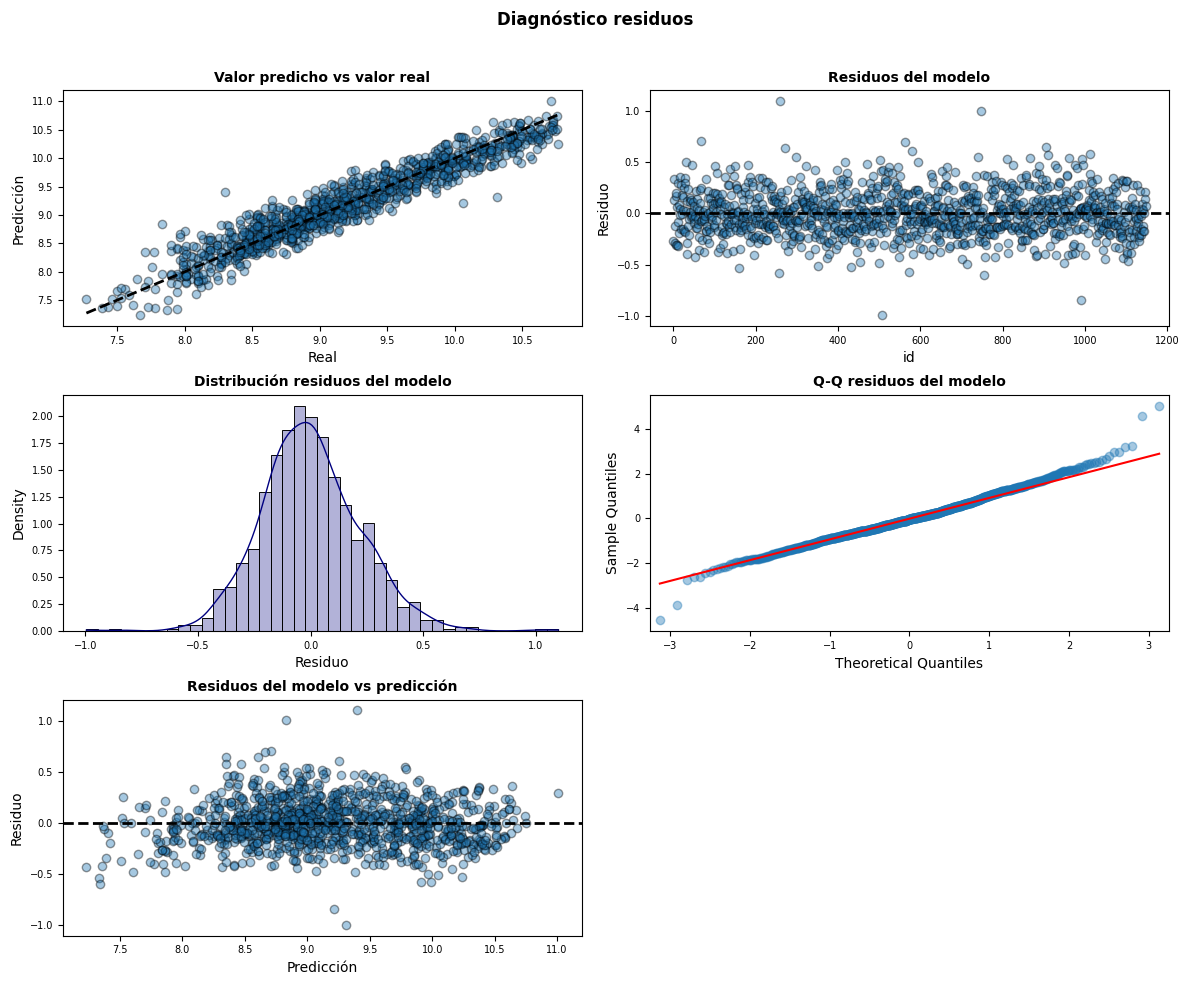

In [242]:
# Gráficos para el pronóstico de residuos

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 10))

axes[0, 0].scatter(y_train, prediccion_train, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()],
                '--', color = 'black', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    color   =  "navy",#"firebrick",
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10,
                     fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train,
    fit   = True,
    line  = 'q',
    ax    = axes[1, 1],
    color = 'navy', #'firebrick',
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

axes[2, 0].scatter(prediccion_train, residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2,1])

fig.tight_layout()
plt.subplots_adjust(top=0.9)
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");

## 7. Evaluación del modelo

El modelo se entrena con el **logaritmo** del precio, así que sus predicciones están en escala logarítmica. Para volver a dólares no basta con `np.exp(predicción)`: eso subestima el precio medio. Se multiplica por el promedio de `exp(error)` de entrenamiento (corrección de Duan, *smearing*). Las métricas en dólares son las que importan para el negocio.

### Entrenamiento

In [243]:
# Factor de corrección para volver de logaritmo a dólares (smearing de Duan)
factor_smearing = np.mean(np.exp(-residuos_train))

# Error de Entrenamiento del modelo (escala logarítmica)
mse = mean_squared_error (y_true = y_train, y_pred = prediccion_train)

print(f"R2   de train (escala log): {r2_score(y_true = y_train, y_pred = prediccion_train):.4f}")
print(f"RMSE de train (escala log): {np.sqrt(mse):.4f}")
print(f"Factor de corrección (smearing): {factor_smearing:.4f}")

# Error de Entrenamiento del modelo (dólares)
metricas_train = metricas_precio(np.exp(y_train), np.exp(prediccion_train) * factor_smearing)
print("\nEntrenamiento (dólares):", {k: round(v, 4) for k, v in metricas_train.items()})

R2   de train (escala log): 0.9140
RMSE de train (escala log): 0.2183
Factor de corrección (smearing): 1.0237

Entrenamiento (dólares): {'R2': 0.8958, 'RMSE': np.float64(3269.9038), 'MAE': 2115.5492, 'MedAE': np.float64(1228.2864)}


### Prueba interna (20 % de los datos)

In [244]:
#Se extraen solo las columnas finales y se adiciona la constante
X_test_const = sm.add_constant(X_test[columnas_finales], has_constant='add')

prediccion_test = modelLRegresion.predict(X_test_const)

# Error de prueba (test) del modelo (escala logarítmica)
print(f"R2   de test (escala log): {r2_score(y_true = y_test, y_pred = prediccion_test):.4f}")
print(f"RMSE de test (escala log): {np.sqrt(mean_squared_error(y_true = y_test, y_pred = prediccion_test)):.4f}")

# Error de prueba (test) del modelo (dólares)
metricas_test = metricas_precio(np.exp(y_test), np.exp(prediccion_test) * factor_smearing)
print("\nPrueba interna (dólares):", {k: round(v, 4) for k, v in metricas_test.items()})

R2   de test (escala log): 0.9094
RMSE de test (escala log): 0.2258

Prueba interna (dólares): {'R2': 0.8797, 'RMSE': np.float64(3256.5109), 'MAE': 2038.538, 'MedAE': np.float64(1216.9421)}


### Prueba real (`Prue`)

El conjunto `Prue` se apartó en el notebook 01 antes de cualquier ajuste y **no se usó en ninguna decisión del modelo** (ni en la selección de variables ni en el escalado), por lo que es la estimación más honesta del desempeño. No se le eliminan atípicos: es lo que el modelo encontraría en la práctica.

In [245]:
#Carga del conjunto de prueba real
dp = pd.read_csv(local_dataset_path_prue)

#Precio real en dólares y logaritmo del precio (variable de salida del modelo)
precio_prue = dp['Price'].copy()
yp = np.log(dp['Price'])

#Dummies: sin 'drop_first' y luego se alinea con las columnas del entrenamiento
#(las categorías de referencia no existen en X; si falta alguna categoría en prueba, su dummy queda en 0)
Xp = pd.get_dummies(dp.drop(columns='Price'), dtype=int)
Xp = Xp.reindex(columns=X.columns, fill_value=0)

#Se escalan las variables numéricas con el escalador ajustado en entrenamiento
Xp[num_vars] = scaler.transform(Xp[num_vars])

#Predicción y retorno a dólares
Xp_const = sm.add_constant(Xp[columnas_finales], has_constant='add')
prediccion_prue = modelLRegresion.predict(Xp_const)
precio_pred_prue = np.exp(prediccion_prue) * factor_smearing

print(f"R2   de Prue (escala log): {r2_score(y_true = yp, y_pred = prediccion_prue):.4f}")
metricas_prue = metricas_precio(precio_prue, precio_pred_prue)
print("\nPrueba real (dólares):", {k: round(v, 4) for k, v in metricas_prue.items()})

R2   de Prue (escala log): 0.8882

Prueba real (dólares): {'R2': 0.76, 'RMSE': np.float64(13229.8833), 'MAE': 5826.9845, 'MedAE': np.float64(1930.9827)}


In [246]:
# Resumen de las métricas en dólares
pd.DataFrame({'Entrenamiento': metricas_train,
              'Prueba interna': metricas_test,
              'Prueba real (Prue)': metricas_prue}).T

,R2,RMSE,MAE,MedAE
Entrenamiento,0.8958,3269.9038,2115.5492,1228.2864
Prueba interna,0.8797,3256.5109,2038.5380,1216.9421
Prueba real (Prue),0.7600,13229.8833,5826.9845,1930.9827


### Análisis de los errores en dólares (prueba real)

In [247]:
# Se arma una tabla con el precio real, el precio predicho y la diferencia absoluta
resultado = pd.DataFrame({'PriceReal': precio_prue.values, 'PricePredict': precio_pred_prue.values})
resultado['dif'] = (resultado['PriceReal'] - resultado['PricePredict']).abs()

# Las diferencias ordenadas
resultado.sort_values(by='dif', ascending=True)

,PriceReal,PricePredict,dif
107,6480.0000,6481.7277,1.7277
37,2580.0000,2608.7115,28.7115
58,6540.0000,6498.3391,41.6609
51,3540.0000,3479.0185,60.9815
140,8388.0000,8296.5841,91.4159
...,...,...,...
13,156000.0000,106651.8502,49348.1498
133,129600.0000,78253.5778,51346.4222
8,150000.0000,85272.8667,64727.1333
62,109200.0000,41736.4857,67463.5143


In [248]:
# Principales descripciones de las diferencias
print(resultado['dif'].describe())

count     206.0000
mean     5826.9845
std     11906.4789
min         1.7277
25%       822.5013
50%      1930.9827
75%      5207.1370
max     91277.4964
Name: dif, dtype: float64


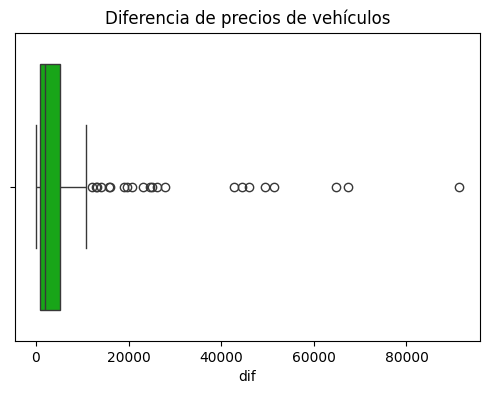

In [249]:
#Caja de bigotes de las diferencias de los precios

plt.figure(figsize=(6,4))

plt.title('Diferencia de precios de vehículos')
sns.boxplot(x=resultado['dif'], palette='nipy_spectral')

plt.show()

#### Referencias

- *Regresion Lineal en Python:*
    - https://www.cienciadedatos.net/documentos/py10-regresion-lineal-python.html
  
  
- *Machine learning con Python y Scikit-learn:*
    - https://www.cienciadedatos.net/documentos/py06_machine_learning_python_scikitlearn.html
    

- *scikit-learn:*    
    - https://scikit-learn.org/stable/
    - https://scikit-learn.org/stable/user_guide.html
  
  
- *Recursive Feature Elimination (RFE)*:
    - https://www.kaggle.com/goyalshalini93/car-price-prediction-linear-regression-rfe
    - https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html


- *Gráficas con  seaborn:*
    - https://ichi.pro/es/como-utilizar-python-seaborn-para-analisis-de-datos-exploratorios-28897898172180


- *Multicolinealidad:*
    - https://www.analyticslane.com/2020/04/22/solucionar-la-multicolinealidad-con-vif/


- *Analítica de grandes datos:*
    - https://jdvelasq.github.io/courses/analitica-de-grandes-datos/index.html